In [20]:
from langgraph.graph import StateGraph,START, END
from typing import TypedDict

In [33]:
#define state
class BMIState(TypedDict):
    height: float
    weight: float
    bmi:float
    category:str

In [21]:
def calculate_bmi(state: BMIState) -> BMIState:
    height = state["height"]
    weight = state["weight"]
    bmi = weight / (height ** 2)
    state["bmi"] = round(bmi,2)
    return state

In [39]:
def predict_category(state:BMIState)->BMIState:
    val=state['bmi']
    output=""
    if val < 18.5:
        output= "Underweight"
    elif val < 25:
        output= "Normal weight"
    elif val < 30:
        output= "Overweight"
    else:
        output= "Obesity"
    state['category']=output
    return state

In [42]:
#define graph
graph=StateGraph(BMIState)

#add nodes to your graph
graph.add_node("calculate_bmi",calculate_bmi)
graph.add_node("predict_category",predict_category)
#add egdes to your graph
graph.add_edge(START,'calculate_bmi')
graph.add_edge('calculate_bmi','predict_category')
graph.add_edge('predict_category',END)

#compile the graph
workflow=graph.compile()


In [43]:
#execute the graph
inital_state={
    "height": 1.75,
    "weight": 70
}
final_state=workflow.invoke(inital_state)
print(final_state)

{'height': 1.75, 'weight': 70, 'bmi': 22.86, 'category': 'Normal weight'}


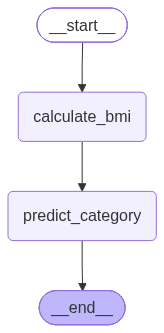

In [37]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())